# 03 — Can revenue outgrow the compute bill?

**Question:** Anthropic has signed up for close to a trillion dollars of compute. How fast must revenue grow to pay for it, and when does the company become *really* profitable, meaning after stock comp and share-paid donations (as defined in notebook 02)?

**Short answer**
1. Fixed compute commitments total **$895B**, plus ~$158B of variable ones (Google TPUs, AMD). Spread by year, they ramp from ~$11B in Q4-2026 to **~$83B in 2027 and ~$130B a year by 2029–30**. That's against a compute bill of ~$40B a year today (§1, `03_compute_commitments.png`).
2. At today's revenue per compute dollar (1.7x in Q3), the commitments are sized for revenue of **~$140B in 2027 and ~$225B in 2029**: the company's own growth forecast, written in contracts (§2).
3. Three scenarios (§3, `03_revenue_vs_compute.png`). **Base**: growth decelerates from 25% a quarter, revenue goes ~$120B (2027) → ~$260B (2030), and it clears breakeven revenue in 2028. **Bear**: 10% a quarter fading fast, revenue ~$81B → ~$106B, never clears it. **Bull**: ~$177B → ~$750B, clears it in 2027.
4. Real profitability (§4, `03_path_to_profit.png`). Base: real operating income turns positive in 2028 (+2%), owner FCF breaks even in 2029 and reaches +10% of revenue in 2030. Bull: positive from 2027. Bear: −45% to −75% margins throughout. The commitments make costs nearly fixed, so revenue works as a lever on margins in both directions.
5. The cash: base and bull fund themselves. In the bear case the $132B pile is down to ~$19B by end-2029 and gone in 2030, unless Anthropic raises capital or uses its termination rights on $214B of commitments (§5, `03_cash.png`).

| § | Question | Chart |
|---|---|---|
| 1 | What has Anthropic already committed to spend on compute, by year? | `03_compute_commitments.png` |
| 2 | What revenue do those commitments imply? | — |
| 3 | How fast might revenue grow, and does it clear breakeven? | `03_revenue_vs_compute.png` |
| 4 | When does Anthropic become really profitable? | `03_path_to_profit.png` |
| 5 | Does the cash last? | `03_cash.png` |

**Inputs:** `data/kpis.csv` (commitments, SBC backlog), `data/contractual_obligations.csv`, `data/real_earnings.csv` (from 02), `data/quarterly_income_statement.csv`, `data/balance_sheet.csv`.
**Outputs:** `data/compute_schedule.csv`, `data/projections.csv`.

Every assumption lives in the `A` and `SCENARIOS` dicts in the first code cell. Change them there, not in the cells below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *

K = load('kpis').drop_duplicates('metric').set_index('metric').value
R = wide(load('real_earnings'), index='metric')
Q = wide(load('quarterly_income_statement'))
bs = wide(load('balance_sheet'))
B = 1000

# --- Assumptions shared by every scenario (cash costs as % of revenue unless noted) ---
A = dict(
    violator_haircut=0.06,  # 02 §3: 5-7% of 2026 revenue is from policy violators being cut off; start from clean Q3
    cash_opex_pct=0.25,     # Q3-2026: S&M+partners 14% + cash personnel 4% + other ex-donations 10% = 28%, some scale leverage
    sbc_new_grants_pct=0.04,  # new grants on top of the backlog; Q3-2026 total SBC was 6.3%
    sbc_ipo_catchup=K['rsu_sbc_catchup_at_ipo'],                      # one-time, IPO quarter (assumed Q4-2026)
    sbc_backlog=K['rsu_unrecognized_sbc'] - K['rsu_sbc_catchup_at_ipo'] + K['option_unrecognized_sbc'],  # spread 2027-2029
    donations_pct=0.03,     # 9M-2026 was 6% (lumpy); company says it will grow; 3% is a middle guess
    capex_pct=0.04,         # owned equipment + prepayments outside the lease commitments (9M-2026: 8.7%, partly lease prepayments)
    tax_rate=0.21,          # on positive operating income; ignores NOLs (conservative)
    cash_yield=0.04,        # interest on the cash pile
)
# --- Scenarios: quarterly growth starts at g0 in Q4-2026, decays toward g_inf with half-life h quarters.
#     r_max = best revenue per $ of compute (Q2-2026 was 2.08x, Q3-2026 1.72x). Compute = max(commitments, revenue / r_max).
SCENARIOS = {
    'Bear': dict(g0=0.10, h=2, g_inf=0.015, r_max=1.6),
    'Base': dict(g0=0.25, h=3, g_inf=0.030, r_max=2.0),
    'Bull': dict(g0=0.40, h=4, g_inf=0.040, r_max=2.5),
}
COLOR = {'Bear': SERIES[1], 'Base': SERIES[0], 'Bull': SERIES[2]}
YEARS = ['Q4-2026', '2027', '2028', '2029', '2030']

## 1. What has Anthropic already committed to spend on compute, by year?
**Why ask:** the S-1's contractual-obligations table shows $320B, but the text below it adds four more layers that bring the total to **$895.4B**. Then come ~$150–175B of arrangements with no fixed price yet. Only the table has a year-by-year schedule, so we estimate one for the rest.

**Method** (each layer is a column in `data/compute_schedule.csv`):
- **Signed contracts (table):** as filed. "Thereafter" is spread evenly over 2031–2035; the Amazon and Google deals run to 2033–2036.
- **Short-term contracts** ($17.4B + $6.6B signed after Sep 30): due within a year, so ¼ in Q4-2026 and ¾ in 2027.
- **Leases not yet started** ($451.2B): they "commence between 2026 and 2028" with ~10-year terms. Half start in 2027 and half in 2028, each paid evenly over 10 years.
- **Signed after Sep 30** ($100.2B, excluding the short-term part): spread with the same yearly profile as the table.
- **Variable** (not fixed-price): Google TPUs, $125–150B delivered 2028–31 with 5-year financing, so the midpoint is paid evenly over 2029–35. AMD, >$20B, paid evenly over 2027–31.

Check: the fixed layers must sum to $895.4B, and our next-12-months figure should land near the S-1's $69.8B.

**Not included:** SpaceXAI's GPUs (~$3.1B/month, up to $120.5B into 2029). It's cancellable on 90 days' notice after early 2027, so it isn't a floor. If kept, it adds ~$37B a year through 2029.

In [2]:
co = load('contractual_obligations')
co = co[co.line_item != 'Total'].groupby('due').value.sum()
yrs = list(range(2026, 2038))
S = pd.DataFrame(0.0, index=yrs, columns=['Signed contracts (table)', 'Short-term contracts', 'Leases not yet started',
                                         'Signed after Sep 30', 'Variable (Google TPU, AMD)'])
for y in range(2026, 2031):
    S.loc[y, 'Signed contracts (table)'] = co[str(y)]
S.loc[2031:2035, 'Signed contracts (table)'] = co['thereafter'] / 5

st = K['commitments_short_term_min'] + K['commitments_after_sep30_short_term']
S.loc[2026, 'Short-term contracts'], S.loc[2027, 'Short-term contracts'] = st / 4, st * 3 / 4

for start in (2027, 2028):
    S.loc[start:start + 9, 'Leases not yet started'] += K['leases_not_commenced'] / 2 / 10

profile = S.loc[2027:, 'Signed contracts (table)']
S.loc[2027:, 'Signed after Sep 30'] = K['commitments_after_sep30'] * profile / profile.sum()

S.loc[2027:2031, 'Variable (Google TPU, AMD)'] += K['commit_amd_variable'] / 5
S.loc[2029:2035, 'Variable (Google TPU, AMD)'] += K['commit_google_tpu_variable'] / 7

fixed = S.drop(columns='Variable (Google TPU, AMD)').sum().sum()
assert abs(fixed - K['commitments_all_in']) < 50, fixed
next12 = S.loc[2026].sum() + 0.75 * S.loc[2027].drop('Variable (Google TPU, AMD)').sum()
print(f'Fixed commitments: ${fixed/B:,.1f}B (S-1: ${K["commitments_all_in"]/B:,.1f}B); + variable ${S["Variable (Google TPU, AMD)"].sum()/B:,.1f}B')
print(f'Our next-12-month estimate: ${next12/B:,.1f}B (S-1: ${K["commitments_due_next_12m"]/B:,.1f}B)')
q3_compute = Q.loc['Compute and infrastructure', 'Q3-2026']
print(f'Today: compute expense ${q3_compute/B:.1f}B in Q3-2026 = ${q3_compute*4/B:.0f}B annualized')
S.index.name = 'year'
S.reset_index().to_csv(DATA / 'compute_schedule.csv', index=False)
(S / B).assign(Total=S.sum(axis=1) / B).round(1)

Fixed commitments: $895.4B (S-1: $895.4B); + variable $157.5B
Our next-12-month estimate: $70.5B (S-1: $69.8B)
Today: compute expense $9.9B in Q3-2026 = $39B annualized


,Signed contracts (table),Short-term contracts,Leases not yet started,Signed after Sep 30,"Variable (Google TPU, AMD)",Total
year,,,,,,
2026,5.2,6.0,0.0,0.0,0.0,11.2
2027,29.2,18.0,22.6,9.3,4.0,83.0
2028,44.4,0.0,45.1,14.1,4.0,107.6
2029,47.8,0.0,45.1,15.2,23.6,131.7
2030,45.1,0.0,45.1,14.3,23.6,128.2
2031,29.7,0.0,45.1,9.4,23.6,107.9
2032,29.7,0.0,45.1,9.4,19.6,103.9
2033,29.7,0.0,45.1,9.4,19.6,103.9
2034,29.7,0.0,45.1,9.4,19.6,103.9


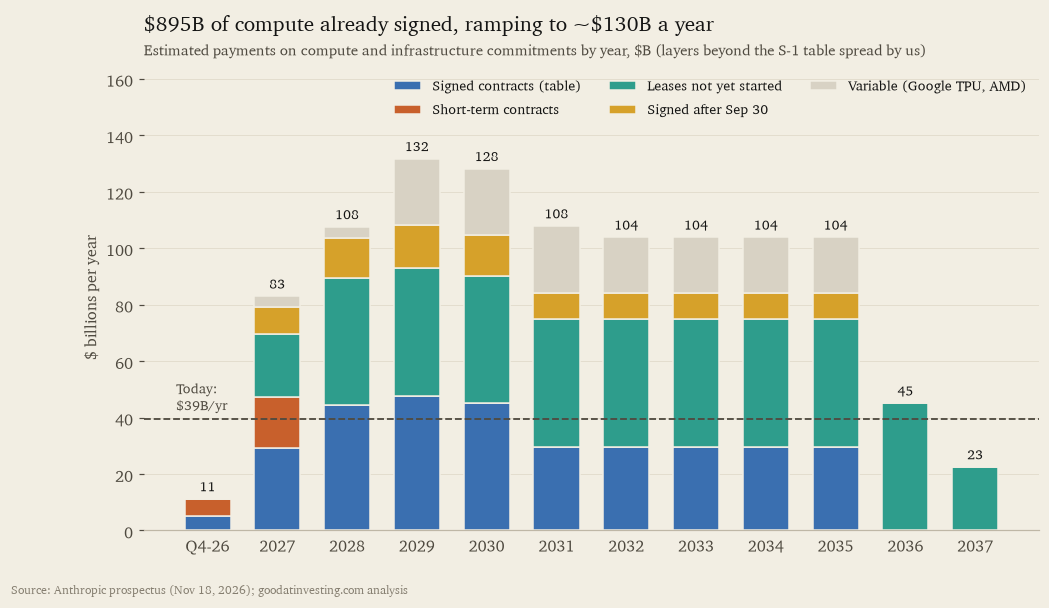

In [3]:
fig, ax = plt.subplots(figsize=(10.5, 5.5))
labels = ['Q4-26'] + [str(y) for y in yrs[1:]]
x = np.arange(len(yrs))
bottom = np.zeros(len(yrs))
fills = SERIES + [PALE]
for col, c in zip(S.columns, fills):
    vals = S[col].values / B
    ax.bar(x, vals, bottom=bottom, color=c, width=0.66, label=col, edgecolor=SURFACE, linewidth=1)
    bottom += vals
for i, t in enumerate(bottom):
    ax.text(i, t + 1.5, f'{t:,.0f}', ha='center', va='bottom', fontsize=9, color=INK)
ax.axhline(q3_compute * 4 / B, color=INK2, lw=1.2, ls='--')
ax.text(-0.45, q3_compute * 4 / B + 2, f'Today:\n${q3_compute*4/B:.0f}B/yr', ha='left', va='bottom', color=INK2, fontsize=9)
ax.set_xticks(x, labels)
ax.tick_params(axis='x', length=0, labelcolor=INK2)
ax.set_ylabel('$ billions per year')
ax.set_ylim(0, 165)
ax.legend(loc='upper right', fontsize=9, ncol=3)
ax.set_title(f'${fixed/B:,.0f}B of compute already signed, ramping to ~$130B a year')
subtitle(ax, 'Estimated payments on compute and infrastructure commitments by year, $B (layers beyond the S-1 table spread by us)')
source(fig)
save(fig, '03_compute_commitments.png')
plt.show()

**What this shows** (`03_compute_commitments.png`): the compute bill roughly **doubles in 2027** and triples by 2029, *whether or not revenue shows up*. Most of these are take-or-pay: if usage falls short, Anthropic pays Google and Amazon a "true-up" anyway. The decline after 2030 doesn't mean spending falls. It's where today's contracts end, and new ones will be signed. So the comparison below stops at 2030.

Two escape valves soften this: **$213.8B** of the total sits in contracts with termination rights or conditions the counterparty must meet (financing, permits), and SpaceXAI can be cancelled on 90 days' notice.

**Next:** what revenue was Anthropic planning for when it signed all this?

## 2. What revenue do those commitments imply?
**Why ask:** nobody signs $130B a year of compute for revenue they don't expect. The commitments are the company's forecast, written in contracts.

**Method:** implied revenue = committed compute × revenue per compute dollar. We use the Q3-2026 ratio (1.72x) and the Q2 peak (2.08x). We also compute the revenue needed for a **real operating breakeven**, i.e. covering committed compute plus cash opex, stock comp (backlog + new grants) and donations:

$$R^* = \frac{\text{compute}_y + \text{SBC backlog}_y}{1 - \text{cash opex\%} - \text{new-grant SBC\%} - \text{donations\%}}$$

In [4]:
rpc = (Q.loc['Revenue'] / Q.loc['Compute and infrastructure'])
print('Revenue per $ of compute by quarter:', rpc.round(2).to_dict())

commit = pd.Series({'Q4-2026': S.loc[2026].sum(), **{str(y): S.loc[y].sum() for y in range(2027, 2031)}})
backlog = pd.Series({'Q4-2026': A['sbc_ipo_catchup'], '2027': A['sbc_backlog'] / 3, '2028': A['sbc_backlog'] / 3,
                     '2029': A['sbc_backlog'] / 3, '2030': 0.0})
margin_left = 1 - A['cash_opex_pct'] - A['sbc_new_grants_pct'] - A['donations_pct']
breakeven = (commit + backlog) / margin_left
implied = pd.DataFrame({'Committed compute': commit, 'Implied revenue @1.72x (Q3)': commit * rpc['Q3-2026'],
                        'Implied revenue @2.08x (Q2)': commit * rpc['Q2-2026'], 'Breakeven revenue (real)': breakeven})
(implied / B).round(0)

Revenue per $ of compute by quarter: {'Q1-2025': 0.4, 'Q2-2025': 0.57, 'Q3-2025': 0.68, 'Q4-2025': 0.69, 'Q1-2026': 1.4, 'Q2-2026': 2.08, 'Q3-2026': 1.72}


,Committed compute,Implied revenue @1.72x (Q3),Implied revenue @2.08x (Q2),Breakeven revenue (real)
Q4-2026,11.0,19.0,23.0,29.0
2027,83.0,143.0,173.0,135.0
2028,108.0,185.0,224.0,171.0
2029,132.0,226.0,274.0,206.0
2030,128.0,220.0,266.0,189.0


**What this shows:** the contracts assume revenue roughly **doubles in 2027** (to ~$140B at Q3 efficiency) and reaches **~$225B in 2029**. Real breakeven needs revenue of ~$135B in 2027, ~$170B in 2028 and ~$205B in 2029. The table is the bar each scenario below has to clear.

Note the circularity: Q3 revenue per compute dollar (1.72x) is high *because* Q2–Q3 revenue arrived before the next wave of compute. The S-1 says margins will compress each time a big block of compute comes online before its revenue does, and 2027 is exactly that.

**Next:** how fast might revenue actually grow?

## 3. How fast might revenue grow, and does it clear breakeven?
**Why ask:** quarter-on-quarter growth went 132% → 144% → 47% through 2026. The question is how fast it fades.

**Method:** start from clean Q3-2026 revenue (reported less 6% for policy violators). Grow it each quarter at a rate that starts at `g0` and decays toward a long-run `g_inf` with a half-life of `h` quarters:

$$g_t = g_\infty + (g_0 - g_\infty)\cdot 0.5^{(t-1)/h}, \qquad \text{Rev}_t = \text{Rev}_{t-1}(1+g_t)$$

- **Bear:** 10% next quarter, halving every 2 quarters toward 1.5% (~6%/yr). Enterprise adoption plateaus, prices fall faster than usage grows.
- **Base:** 25%, half-life 3 quarters, toward 3% (~12.5%/yr).
- **Bull:** 40%, half-life 4 quarters, toward 4% (~17%/yr). Agents keep compounding.

FY2026 revenue (9M actual + Q4 projected): {'Bear': 50.8, 'Base': 53.2, 'Bull': 55.6}


,Q4-2026,2027,2028,2029,2030
Bear,18.0,81.0,92.0,99.0,106.0
Base,20.0,120.0,176.0,222.0,261.0
Bull,22.0,177.0,355.0,551.0,746.0


,2027 growth %,2028 growth %,2029 growth %,2030 growth %
Bear,60.0,13.0,8.0,7.0
Base,125.0,47.0,26.0,18.0
Bull,218.0,101.0,55.0,35.0


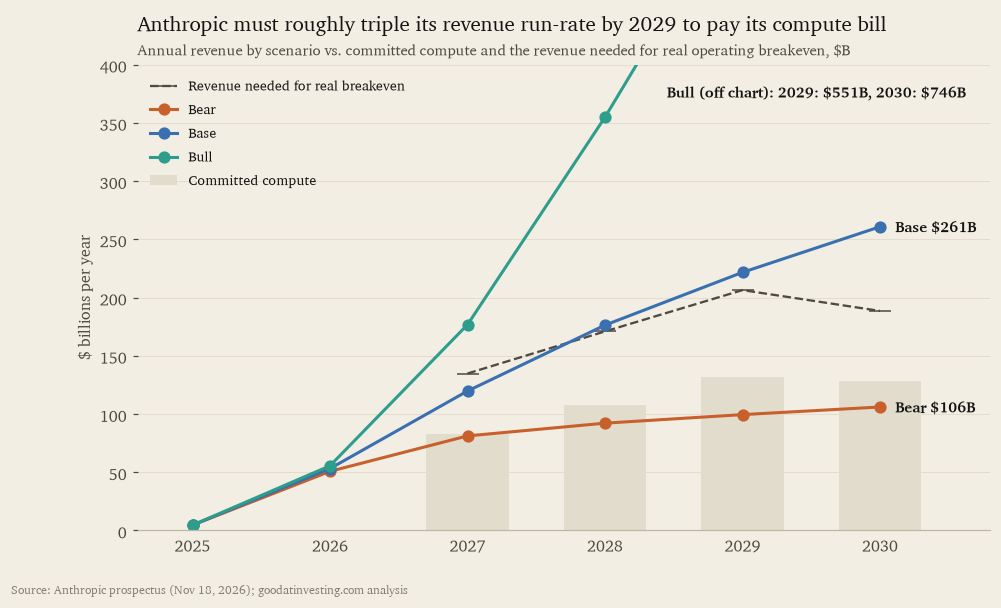

In [5]:
start = Q.loc['Revenue', 'Q3-2026'] * (1 - A['violator_haircut'])
quarters = [f'Q{(i + 2) % 4 + 1}-{2026 + (i + 2) // 4}' for i in range(1, 18)]  # Q4-2026 .. Q4-2030

def revenue_path(g0, h, g_inf, **_):
    r, out = start, []
    for t in range(1, len(quarters) + 1):
        r *= 1 + g_inf + (g0 - g_inf) * 0.5 ** ((t - 1) / h)
        out.append(r)
    return pd.Series(out, index=quarters)

def to_years(qs):
    return qs.groupby(lambda q: 'Q4-2026' if q == 'Q4-2026' else q[-4:]).sum().reindex(YEARS)

rev = pd.DataFrame({s: to_years(revenue_path(**p)) for s, p in SCENARIOS.items()})
fy2026 = R.loc['revenue', '9M-2026'] + rev.loc['Q4-2026']
growth = rev.loc[['2027', '2028', '2029', '2030']].pct_change()
growth.loc['2027'] = rev.loc['2027'] / fy2026 - 1
print('FY2026 revenue (9M actual + Q4 projected):', (fy2026 / B).round(1).to_dict())
display((rev / B).round(0).T, (growth * 100).round(0).T.rename(columns=lambda c: c + ' growth %'))

fig, ax = plt.subplots(figsize=(10, 5.5))
years_axis = ['2025', '2026', '2027', '2028', '2029', '2030']
x = np.arange(len(years_axis))
ax.bar(x[2:], commit[['2027', '2028', '2029', '2030']] / B, color=GRID, width=0.6, label='Committed compute')
ax.plot(x[2:], breakeven[['2027', '2028', '2029', '2030']] / B, color=INK2, ls='--', lw=1.5, marker='_', markersize=14,
        label='Revenue needed for real breakeven')
hist = [R.loc['revenue', 'FY2025']]
TOP = 400
for s in SCENARIOS:
    ys = np.r_[hist, fy2026[s], rev.loc[['2027', '2028', '2029', '2030'], s]] / B
    ax.plot(x, ys, color=COLOR[s], marker='o', label=s, clip_on=True)
    if ys[-1] < TOP:
        ax.annotate(f'{s} ${ys[-1]:,.0f}B', (x[-1], ys[-1]), xytext=(10, 0), textcoords='offset points', va='center',
                    color=INK, fontsize=9.5, fontweight='bold')
    else:  # bull runs off the top: name its exit values instead of squashing the other lines
        off = [f"{y}: ${v:,.0f}B" for y, v in zip(years_axis, ys) if v >= TOP]
        ax.annotate(f'{s} (off chart): ' + ', '.join(off), (x[np.argmax(ys >= TOP)] - 0.55, TOP * 0.96), ha='left', va='top',
                    color=INK, fontsize=9.5, fontweight='bold')
ax.set_ylim(0, TOP)
ax.set_xticks(x, years_axis)
ax.tick_params(axis='x', length=0, labelcolor=INK2)
ax.set_xlim(-0.4, len(x) - 0.2)
ax.set_ylabel('$ billions per year')
ax.legend(loc='upper left', fontsize=9)
ax.set_title('Anthropic must roughly triple its revenue run-rate by 2029 to pay its compute bill')
subtitle(ax, 'Annual revenue by scenario vs. committed compute and the revenue needed for real operating breakeven, $B')
source(fig)
save(fig, '03_revenue_vs_compute.png')
plt.show()

**What this shows** (`03_revenue_vs_compute.png`): the dashed line is the bar. **Base** more than doubles in 2027 (+125% on FY2026, mostly 2026's exit rate carrying over), adds +47% in 2028, and crosses breakeven in 2028. **Bull** is above it from 2027; there, compute is the constraint, not demand. **Bear** still grows 60% in 2027 on 2026's momentum, then slows to high single digits. That's still a $100B-revenue company, and it never gets there: the cost base was signed for a much faster company.

**06 puts these in context:** with ceiling-bounded growth curves and a TAM-sized ceiling, the base case lands at about the 30th percentile. The bear case falls below every simulated world, because it needs revenue to stall near today's run-rate. Treat it as a stress test, not a central case.

That's the core of the investment case. A merely good outcome loses money for years, because the costs were set for a great one.

**Next:** turn the gap into margins and cash.

## 4. When does Anthropic become really profitable?
**Method:** for each scenario and year:
- **Compute** = max(committed compute, revenue ÷ `r_max`). Below the commitments you pay anyway; above them you buy more, at no better than `r_max` revenue per dollar.
- **Real operating income** = revenue − compute − cash opex − SBC (IPO catch-up, backlog, new grants) − donations. This is 02's definition.
- **Owner FCF** = real operating income − tax (on positive income) − capex. Stock comp and donations stay deducted as owner costs.
- **FCF** (the conventional measure) = owner FCF + SBC + donations + interest income. Used in §5 for the cash balance.

Compute payments are treated as cash costs in the year due. Most are CSP fees and lease rent, which is how they hit the P&L too.

In [6]:
def model(name, p):
    r = rev[name]
    compute = np.maximum(commit, r / p['r_max'])
    sbc = backlog + A['sbc_new_grants_pct'] * r
    don = A['donations_pct'] * r
    real_oi = r - compute - A['cash_opex_pct'] * r - sbc - don
    tax = A['tax_rate'] * real_oi.clip(lower=0)
    capex = A['capex_pct'] * r
    owner_fcf = real_oi - tax - capex
    cash, cash_end, interest = bs.loc[['Cash and cash equivalents', 'Short-term investments'], '2026-09-30'].sum(), [], []
    for y in YEARS:
        i = cash * A['cash_yield'] * (0.25 if y == 'Q4-2026' else 1)
        cash += owner_fcf[y] + sbc[y] + don[y] + i
        interest.append(i); cash_end.append(cash)
    return pd.DataFrame({'revenue': r, 'compute': compute, 'compute_floor_binding': compute == commit, 'sbc': sbc, 'donations': don,
                         'real_operating_income': real_oi, 'real_operating_margin': real_oi / r, 'owner_fcf': owner_fcf,
                         'owner_fcf_margin': owner_fcf / r, 'interest_income': interest,
                         'fcf': owner_fcf + sbc + don + np.array(interest), 'cash_end': cash_end}, index=YEARS)

M = {s: model(s, p) for s, p in SCENARIOS.items()}
for s, m in M.items():
    print(f'--- {s}')
    display(m.drop(columns=['compute_floor_binding']).T.style.format(lambda v: f'{v:.0%}' if abs(v) < 5 else f'{v/B:,.1f}'))

--- Bear


,Q4-2026,2027,2028,2029,2030
revenue,17.5,81.2,92.1,99.5,106.0
compute,11.2,83.0,107.6,131.7,128.2
sbc,8.9,11.9,12.3,12.6,4.2
donations,0.5,2.4,2.8,3.0,3.2
real_operating_income,-7.5,-36.4,-53.6,-72.7,-56.1
real_operating_margin,-43%,-45%,-58%,-73%,-53%
owner_fcf,-8.2,-39.7,-57.3,-76.7,-60.3
owner_fcf_margin,-47%,-49%,-62%,-77%,-57%
interest_income,1.3,5.4,4.6,3.1,0.8
fcf,2.5,-20.0,-37.6,-58.0,-52.1


--- Base


,Q4-2026,2027,2028,2029,2030
revenue,19.9,119.7,176.3,221.6,260.8
compute,11.2,83.0,107.6,131.7,130.4
sbc,9.0,13.4,15.7,17.5,10.4
donations,0.6,3.6,5.3,6.6,7.8
real_operating_income,-5.9,-10.2,3.7,10.4,46.9
real_operating_margin,-30%,-9%,2%,5%,18%
owner_fcf,-6.7,-15.0,-4.2,-0.7,26.7
owner_fcf_margin,-34%,-13%,-2%,-0%,10%
interest_income,1.3,5.4,5.7,6.6,7.8
fcf,4.2,7.5,22.6,30.1,52.8


--- Bull


,Q4-2026,2027,2028,2029,2030
revenue,22.3,176.7,354.8,551.3,746.1
compute,11.2,83.0,141.9,220.5,298.5
sbc,9.1,15.7,22.8,30.7,29.8
donations,0.7,5.3,10.6,16.5,22.4
real_operating_income,-4.3,28.5,90.7,145.7,208.9
real_operating_margin,-19%,16%,26%,26%,28%
owner_fcf,-5.1,15.5,57.5,93.1,135.2
owner_fcf_margin,-23%,9%,16%,17%,18%
interest_income,1.3,5.5,7.2,11.1,17.2
fcf,5.9,42.0,98.1,151.4,204.6


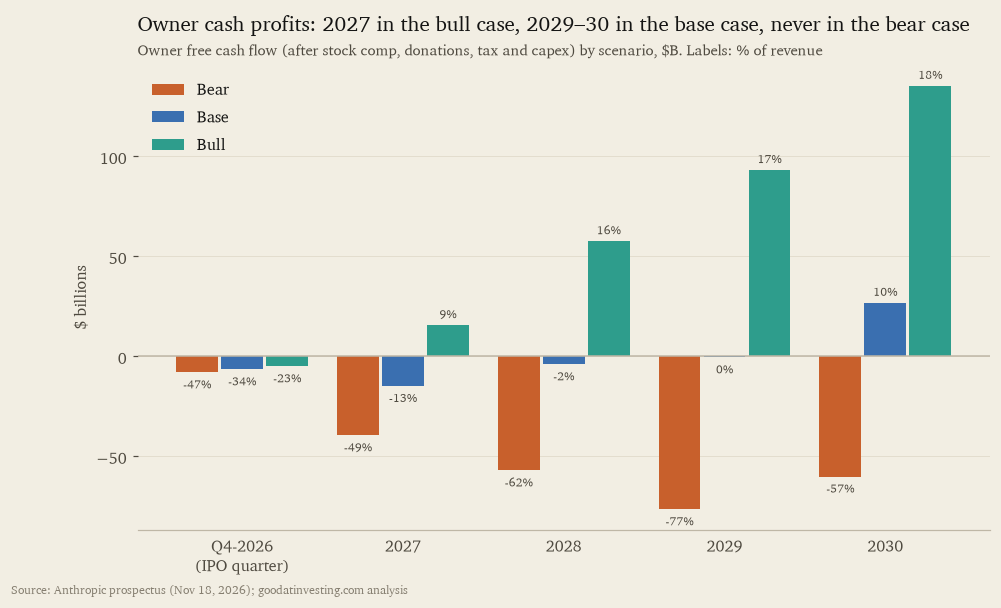

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(YEARS))
w = 0.26
for k, s in enumerate(SCENARIOS):
    v = M[s]['owner_fcf'] / B
    ax.bar(x + (k - 1) * (w + 0.02), v, width=w, color=COLOR[s], label=s)
    for xi, vi, mi in zip(x, v, M[s]['owner_fcf_margin']):
        ax.text(xi + (k - 1) * (w + 0.02), vi + (2 if vi >= 0 else -2), f'{mi:.0%}'.replace('-0%', '0%'), ha='center',
                va='bottom' if vi >= 0 else 'top', fontsize=8, color=INK2)
ax.axhline(0, color=AXIS, lw=1)
ax.set_xticks(x, ['Q4-2026\n(IPO quarter)', '2027', '2028', '2029', '2030'])
ax.tick_params(axis='x', length=0, labelcolor=INK2)
ax.set_ylabel('$ billions')
ax.legend(loc='upper left')
ax.set_title('Owner cash profits: 2027 in the bull case, 2029–30 in the base case, never in the bear case')
subtitle(ax, 'Owner free cash flow (after stock comp, donations, tax and capex) by scenario, $B. Labels: % of revenue')
source(fig)
save(fig, '03_path_to_profit.png')
plt.show()

**What this shows** (`03_path_to_profit.png`): the IPO quarter is ugly in every scenario, with the ~$8B stock-comp catch-up landing on top of a compute step-up. 2027 is the test year. Committed compute roughly doubles, so revenue has to roughly double just to hold margins.

- **Base:** real operating loss of ~$10B in 2027, slightly positive in 2028, and owner FCF breakeven in 2029. Then +10% of revenue (~$27B) in 2030 as revenue outgrows the commitments.
- **Bull:** profitable from 2027. Compute stops being a floor and becomes a ceiling (`compute_floor_binding` = False), so the binding question becomes how much more compute it can get.
- **Bear:** deeply negative throughout. Fixed take-or-pay compute plus a stock-comp backlog swamp ~20%+ revenue growth.

The model is deliberately simple. Compute is the only cost that doesn't scale with revenue, so the answer mostly hinges on two numbers: **revenue growth** and **revenue per compute dollar**.

**Next:** in the bad cases, does the money run out?

## 5. Does the cash last?
**Method:** start from $131.8B of cash and short-term investments at Sep 30, 2026. Add FCF each year (SBC and donations are non-cash, so they're added back here) plus 4% interest. IPO proceeds, the $14.8B undrawn revolver and the $77B of undrawn partner note facilities are **excluded**: they're the cushion.

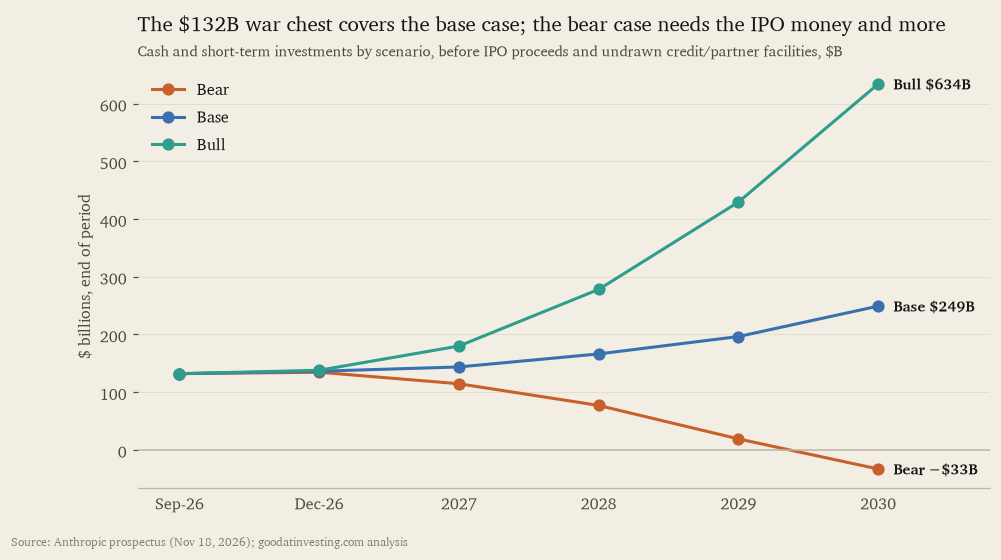

165 rows -> data/projections.csv


In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(YEARS) + 1)
for s in SCENARIOS:
    ys = np.r_[M[s]['cash_end'].iloc[0] - M[s]['fcf'].iloc[0], M[s]['cash_end']] / B
    ax.plot(x, ys, color=COLOR[s], marker='o', label=s)
    lab = f'−${-ys[-1]:,.0f}B' if ys[-1] < 0 else f'${ys[-1]:,.0f}B'
    ax.annotate(f'{s} {lab}', (x[-1], ys[-1]), xytext=(10, 0), textcoords='offset points', va='center',
                color=INK, fontsize=9.5, fontweight='bold')
ax.axhline(0, color=AXIS, lw=1)
ax.set_xticks(x, ['Sep-26', 'Dec-26', '2027', '2028', '2029', '2030'])
ax.tick_params(axis='x', length=0, labelcolor=INK2)
ax.set_xlim(-0.3, len(x) - 0.2)
ax.set_ylabel('$ billions, end of period')
ax.legend(loc='upper left')
ax.set_title('The $132B war chest covers the base case; the bear case needs the IPO money and more')
subtitle(ax, 'Cash and short-term investments by scenario, before IPO proceeds and undrawn credit/partner facilities, $B')
source(fig)
save(fig, '03_cash.png')
plt.show()

out = pd.concat([m.assign(scenario=s) for s, m in M.items()]).reset_index(names='period')
out = out.melt(id_vars=['scenario', 'period'], var_name='metric').query('metric != "compute_floor_binding"')
out.to_csv(DATA / 'projections.csv', index=False)
print(len(out), 'rows -> data/projections.csv')

**What this shows** (`03_cash.png`): base and bull never need new money. The bear case burns through the cash pile by 2030 (~$19B left at end-2029) and has to choose: raise more (IPO proceeds and partner facilities buy time), or use the termination rights on ~$214B of conditional commitments and shrink the training budget. That would mean ceding the frontier, which is the whole product.

## Findings, by section
1. Fixed compute commitments are $895B (S-1 total, reconciled), plus ~$158B variable. By our spread, that's ~$83B in 2027 and ~$130B a year in 2029–30, vs ~$40B a year today.
2. At Q3-2026 revenue per compute dollar (1.72x), the commitments imply revenue of ~$140B in 2027 and ~$225B in 2029. Real breakeven needs about the same.
3. Base revenue: ~$120B (2027) → ~$260B (2030). Bull: ~$177B → ~$750B. Bear: ~$81B → ~$106B. Breakeven revenue is ~$135B (2027), ~$170B (2028), ~$205B (2029).
4. Real operating income > 0: base 2028, bull 2027, bear never. Owner FCF > 0: base 2030 (breakeven 2029), bull 2027, bear never.
5. Base and bull are self-funding from the $132B pile. The bear case runs out of cash in 2030 without new capital or cancellations.

**Caveats**
- Payment timing for the $575B outside the S-1 table is our estimate. The total and the next-12-months figure are checked against the S-1; the shape is not.
- Commitments are treated as cash cost in the year due. Lease accounting will smooth the P&L, but the cash goes out as scheduled.
- Real opex (cash opex 25%, donations 3%, new-grant SBC 4%) is held flat as a share of revenue. Sales/partner fees should fall as direct sales grow (upside); donations are policy-driven and could rise (downside).
- Price cuts are inside the growth rates. The S-1 cites ~25–40% per-task cost cuts with each model release, so usage must grow faster than revenue.
- Taxes ignore NOLs; interest ignores IPO proceeds.

**Open items:** add the IPO proceeds and final share count once priced. Notebook 04 could turn owner FCF into a valuation (per-share, diluted for the 1.84B note shares and the SBC backlog).